In [2]:
!pip install "numpy<2"

# P2 Tumor Cropping Pipeline, Nov 15 Milestone

In [1]:
## script in crop_tumor.py

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset

import brain_mri_data
from brain_mri_data import (
    PROJECT_ROOT,
    LABELS,
    LABEL_TO_IDX,
    IMG_SIZE,
    BrainMRIDataset,
    denormalize,
    load_splits,
)

print(f"PyTorch version: {torch.__version__}")
print(f"Device: {'mps' if torch.backends.mps.is_available() else 'cuda' if torch.cuda.is_available() else 'cpu'}")
print(f"Project root: {PROJECT_ROOT}")

PyTorch version: 2.12.1
Device: mps
Project root: /Users/anikalindell/539/Integration_Project


### Implementation: Bounding Box Calculation & Cropping Module

In [3]:
def compute_tumor_bounding_box(mask, pad_frac=0.20, min_size=48):
    """Compute an aspect-ratio-preserving square bounding box covering all tumor regions.
    
    Args:
        mask: Tensor [1, H, W] or [H, W], or numpy array (binary 0/1).
        pad_frac: Proportional padding to expand around the tumor (default 0.20 = 20%).
        min_size: Minimum width/height in pixels for the crop (default 48 px).
        
    Returns:
        tuple (y1, y2, x1, x2) or None if mask is empty.
    """
    if isinstance(mask, torch.Tensor):
        if mask.dim() == 3:
            mask = mask[0]
        pos = (mask > 0.5).nonzero(as_tuple=False)
        if len(pos) == 0:
            return None
        y_min = pos[:, 0].min().item()
        y_max = pos[:, 0].max().item()
        x_min = pos[:, 1].min().item()
        x_max = pos[:, 1].max().item()
        h_img, w_img = mask.shape
    else:
        mask = np.squeeze(mask)
        pos = np.argwhere(mask > 0.5)
        if len(pos) == 0:
            return None
        y_min = pos[:, 0].min()
        y_max = pos[:, 0].max()
        x_min = pos[:, 1].min()
        x_max = pos[:, 1].max()
        h_img, w_img = mask.shape

    raw_h = y_max - y_min + 1
    raw_w = x_max - x_min + 1

    # Ensure square crop to preserve anatomical aspect ratio
    side = max(raw_h, raw_w)
    side = int(round(side * (1.0 + 2.0 * pad_frac)))
    side = max(side, min_size)
    side = min(side, min(h_img, w_img))

    # Center crop around the multi-region centroid
    cy = (y_min + y_max) // 2
    cx = (x_min + x_max) // 2

    y1 = cy - side // 2
    x1 = cx - side // 2
    y2 = y1 + side
    x2 = x1 + side

    # Shift box if it spills over image boundaries
    if y1 < 0:
        y2 += -y1
        y1 = 0
    elif y2 > h_img:
        y1 -= (y2 - h_img)
        y2 = h_img

    if x1 < 0:
        x2 += -x1
        x1 = 0
    elif x2 > w_img:
        x1 -= (x2 - w_img)
        x2 = w_img

    # Clamp within image bounds
    y1 = max(0, min(y1, h_img - 1))
    y2 = max(y1 + 1, min(y2, h_img))
    x1 = max(0, min(x1, w_img - 1))
    x2 = max(x1 + 1, min(x2, w_img))

    return y1, y2, x1, x2


def crop_tumor_image(image, mask=None, pad_frac=0.20, min_size=48, notumor_mode='full_slice', target_size=IMG_SIZE):
    """Crop tumor patch from image tensor [3, H, W] and resize back to target_size (224x224)."""
    box = None
    if mask is not None:
        box = compute_tumor_bounding_box(mask, pad_frac=pad_frac, min_size=min_size)

    if box is None:
        # No-tumor handling: return full slice so classifier cannot exploit empty-crop shortcut
        if notumor_mode == 'full_slice':
            if image.shape[-2:] == (target_size, target_size):
                return image.clone(), None
            crop = image
        else:
            raise ValueError(f"Unsupported notumor_mode: {notumor_mode}")
    else:
        y1, y2, x1, x2 = box
        crop = image[:, y1:y2, x1:x2]

    # Bilinear interpolation back to 224x224
    crop_4d = crop.unsqueeze(0)
    resized = F.interpolate(crop_4d, size=(target_size, target_size), mode='bilinear', align_corners=False)
    return resized.squeeze(0), box


class CroppedBrainMRIDataset(Dataset):
    """Dataset yielding cropped tumor patches for P3 classification training."""
    def __init__(self, split, root=PROJECT_ROOT, keep_aspect=True, hflip=False, pad_frac=0.20, min_size=48, notumor_mode='full_slice'):
        self.base_ds = BrainMRIDataset(split, root=root, keep_aspect=keep_aspect, hflip=hflip)
        self.pad_frac = pad_frac
        self.min_size = min_size
        self.notumor_mode = notumor_mode

    def __len__(self):
        return len(self.base_ds)

    def __getitem__(self, i):
        item = self.base_ds[i]
        full_image = item['image']
        mask = item['mask']
        cropped_img, box = crop_tumor_image(
            full_image,
            mask=mask if item['has_mask'] else None,
            pad_frac=self.pad_frac,
            min_size=self.min_size,
            notumor_mode=self.notumor_mode,
        )
        return {
            'image': cropped_img,               # [3, 224, 224] cropped & normalized for ResNet
            'full_image': full_image,           # [3, 224, 224] original full slice
            'mask': mask,                       # [1, 224, 224] ground truth mask
            'has_mask': item['has_mask'],
            'label': item['label'],
            'path': item['path'],
            'crop_box': torch.tensor(box if box is not None else [-1, -1, -1, -1], dtype=torch.int32),
        }


def make_cropped_loader(split, batch_size=32, root=PROJECT_ROOT, shuffle=None, num_workers=0, **kwargs):
    dataset = CroppedBrainMRIDataset(split, root=root, **kwargs)
    if shuffle is None:
        shuffle = (split == 'train')
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle, num_workers=num_workers)

print("Cropping pipeline defined successfully!")

Cropping pipeline defined successfully!


### Nov 15 Deliverable: 8-Sample Visual Verification on Dev Split
Visualizes the full slice with ground truth mask (red) and calculated square bounding box (cyan), alongside the resulting 224×224 cropped input for P3.

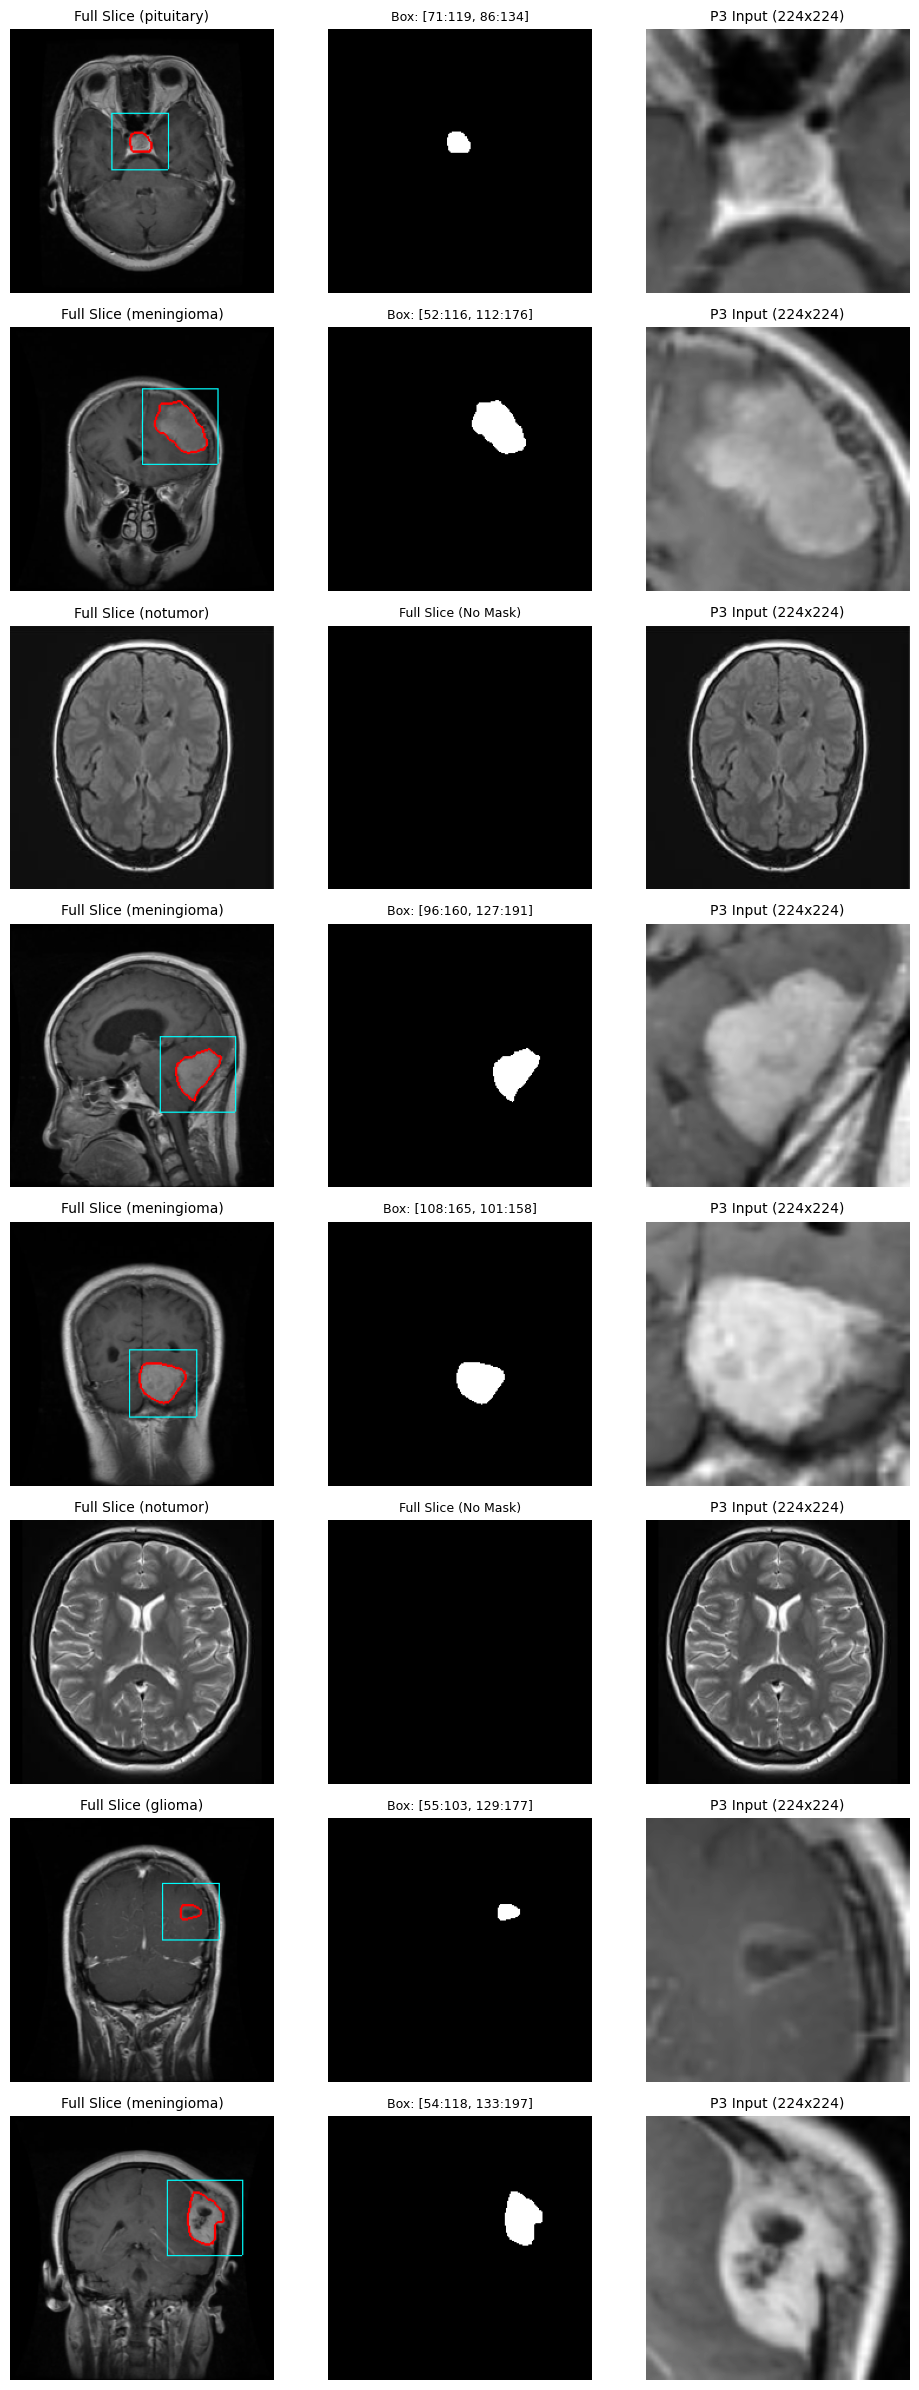

Saved visual preview to: nov15_cropped_preview.png


In [4]:
# Load 8 samples from the dev split
dev_loader = make_cropped_loader('dev', batch_size=8, shuffle=True)
batch = next(iter(dev_loader))

fig, axes = plt.subplots(len(batch['image']), 3, figsize=(10, 3 * len(batch['image'])))

for i in range(len(batch['image'])):
    label_name = LABELS[batch['label'][i]]
    has_mask = batch['has_mask'][i].item()
    box = batch['crop_box'][i].numpy()

    # Column 1: Full slice with mask outline (red) and bounding box (cyan)
    orig_gray = denormalize(batch['full_image'][i]).numpy()
    orig_rgb = np.stack([orig_gray] * 3, axis=-1)
    if has_mask:
        m = batch['mask'][i, 0].numpy() > 0.5
        edge = m & ~ndimage.binary_erosion(m, iterations=2)
        orig_rgb[edge] = [1.0, 0.0, 0.0]
        if (box >= 0).all():
            y1, y2, x1, x2 = box
            orig_rgb[max(0, y1):min(224, y2), max(0, x1)] = [0.0, 1.0, 1.0]
            orig_rgb[max(0, y1):min(224, y2), max(0, min(223, x2))] = [0.0, 1.0, 1.0]
            orig_rgb[max(0, y1), max(0, x1):min(224, x2)] = [0.0, 1.0, 1.0]
            orig_rgb[max(0, min(223, y2)), max(0, x1):min(224, x2)] = [0.0, 1.0, 1.0]

    axes[i, 0].imshow(orig_rgb)
    axes[i, 0].set_title(f"Full Slice ({label_name})", fontsize=10)
    axes[i, 0].axis('off')

    # Column 2: Ground truth mask
    mask_disp = batch['mask'][i, 0].numpy()
    axes[i, 1].imshow(mask_disp, cmap='gray')
    box_str = f"Box: [{box[0]}:{box[1]}, {box[2]}:{box[3]}]" if (box >= 0).all() else "Full Slice (No Mask)"
    axes[i, 1].set_title(box_str, fontsize=9)
    axes[i, 1].axis('off')

    # Column 3: Resulting cropped & resized patch for P3
    crop_gray = denormalize(batch['image'][i]).numpy()
    axes[i, 2].imshow(crop_gray, cmap='gray')
    axes[i, 2].set_title(f"P3 Input (224x224)", fontsize=10)
    axes[i, 2].axis('off')

plt.tight_layout()
plt.savefig('nov15_cropped_preview.png', dpi=150)
plt.show()
print("Saved visual preview to: nov15_cropped_preview.png")

### Quantitative Verification Across All 4 Classes
Verifies crop dimensions, boundary compliance, and no-tumor preservation across the entire dev set.

In [6]:
# Run sanity check over 100 dev samples
dev_ds = CroppedBrainMRIDataset('dev')
stats = []

for idx in range(min(100, len(dev_ds))):
    item = dev_ds[idx]
    label = LABELS[item['label']]
    box = item['crop_box'].numpy()
    has_mask = item['has_mask']
    
    if has_mask and (box >= 0).all():
        box_h = box[1] - box[0]
        box_w = box[3] - box[2]
        stats.append({'label': label, 'has_mask': True, 'box_size': box_h, 'is_square': box_h == box_w})
    else:
        stats.append({'label': label, 'has_mask': False, 'box_size': 224, 'is_square': True})

stats_df = pd.DataFrame(stats)
print("=== Crop Verification Summary (First 100 dev samples) ===")
print(f"All crops square (aspect preserved): {stats_df['is_square'].all()}")
print(f"All crop image shapes are 3x224x224: {item['image'].shape == (3, 224, 224)}")
print("Median crop box size by class (before resize to 224):")
print(stats_df.groupby('label')['box_size'].median())

=== Crop Verification Summary (First 100 dev samples) ===
All crops square (aspect preserved): True
All crop image shapes are 3x224x224: True
Median crop box size by class (before resize to 224):
label
meningioma    59.0
pituitary     48.0
Name: box_size, dtype: float64
